In [22]:
from sklearn.datasets import fetch_lfw_people
from PIL import Image
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [24]:
MIN_FACES_PER_PERSON = 20
SEED = 42
DATA_DIR = "./data"

### Check Data

In [3]:
def load_lfw(min_faces_per_person: int = MIN_FACES_PER_PERSON):
    lfw = fetch_lfw_people(
        data_home=str(DATA_DIR),
        min_faces_per_person=min_faces_per_person,
        color=True,
        resize=1.0,
        funneled=True,
    )
    images = lfw.images
    if images.max() <= 1.0:  # sklearn scales pixels to [0, 1]
        images = images * 255.0
    images = np.clip(images, 0, 255).astype(np.uint8)
    labels = lfw.target.astype(np.int64)
    class_names = [str(n) for n in lfw.target_names]
    return images, labels, class_names

In [4]:
def to_pil_image(image: np.ndarray) -> Image.Image:
    return Image.fromarray(image)

In [5]:
images, labels, class_names = load_lfw()

In [13]:
images.shape, labels.shape, len(class_names)

((3023, 125, 94, 3), (3023,), 62)

In [7]:
images[1].min(), images[1].max()

(np.uint8(0), np.uint8(255))

In [8]:
class_names[labels[1]]

'Jean Chretien'

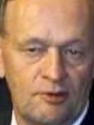

In [9]:
pil_image = to_pil_image(images[1])
pil_image

In [15]:
df_counts = (
    pd.Series(labels)
    .value_counts()
    .sort_index()
    .rename_axis("label")
    .reset_index(name="count")
)

df_counts["class_name"] = df_counts["label"].map(
    dict(enumerate(class_names))
)

df_counts = df_counts[["label", "class_name", "count"]]

In [18]:
df_counts['count'].max(), df_counts['count'].min()

(530, 20)

In [17]:
df_counts['count'].value_counts()

count
20     5
22     5
21     4
24     3
23     3
32     3
33     3
39     2
42     2
29     2
31     2
26     2
30     2
28     2
52     2
41     2
35     1
36     1
77     1
236    1
121    1
530    1
109    1
44     1
71     1
55     1
53     1
60     1
48     1
37     1
27     1
25     1
144    1
49     1
Name: count, dtype: int64

### Split Data

In [20]:
def make_splits(labels, val_frac=0.15, test_frac=0.15):
    idx = np.arange(len(labels))
    holdout = val_frac + test_frac
    train_idx, rest_idx = train_test_split(
        idx, test_size=holdout, stratify=labels, random_state=SEED
    )
    val_idx, test_idx = train_test_split(
        rest_idx,
        test_size=test_frac / holdout,
        stratify=labels[rest_idx],
        random_state=SEED,
    )
    return train_idx, val_idx, test_idx

In [25]:
train_idx, val_idx, _ = make_splits(labels)

In [27]:
train_idx.shape, val_idx.shape

((2116,), (453,))

In [30]:
df_train = pd.DataFrame({
    "label": labels[train_idx]
}).value_counts().reset_index(name="count")

df_train["class_name"] = df_train["label"].map(dict(enumerate(class_names)))
df_train = df_train[["label", "class_name", "count"]].sort_values("label").reset_index(drop=True)

df_val = pd.DataFrame({
    "label": labels[val_idx]
}).value_counts().reset_index(name="count")

df_val["class_name"] = df_val["label"].map(dict(enumerate(class_names)))
df_val = df_val[["label", "class_name", "count"]].sort_values("label").reset_index(drop=True)

In [31]:
df_train

,label,class_name,count
0,0,Alejandro Toledo,27
1,1,Alvaro Uribe,25
2,2,Amelie Mauresmo,15
3,3,Andre Agassi,25
4,4,Angelina Jolie,14
...,...,...,...
57,57,Tom Ridge,23
58,58,Tony Blair,101
59,59,Vicente Fox,22
60,60,Vladimir Putin,34


In [32]:
df_val

,label,class_name,count
0,0,Alejandro Toledo,6
1,1,Alvaro Uribe,5
2,2,Amelie Mauresmo,3
3,3,Andre Agassi,5
4,4,Angelina Jolie,3
...,...,...,...
57,57,Tom Ridge,5
58,58,Tony Blair,21
59,59,Vicente Fox,5
60,60,Vladimir Putin,7


In [33]:
df_train['count'].value_counts()

count
15     8
14     5
22     5
29     4
20     4
16     4
17     3
18     3
23     3
27     2
25     2
21     2
36     2
34     2
54     1
165    1
85     1
371    1
76     1
31     1
50     1
39     1
37     1
42     1
26     1
19     1
101    1
Name: count, dtype: int64

In [34]:
df_val['count'].value_counts()

count
4     19
5     12
3     10
6      7
8      4
7      2
11     1
35     1
18     1
79     1
16     1
10     1
9      1
21     1
Name: count, dtype: int64

In [36]:
df_train[df_train["class_name"] == "Alejandro Toledo"]

,label,class_name,count
0,0,Alejandro Toledo,27


In [37]:
df_val[df_val["class_name"] == "Alejandro Toledo"]

,label,class_name,count
0,0,Alejandro Toledo,6


In [39]:
df_train[df_train["class_name"] == "Alvaro Uribe"]

,label,class_name,count
1,1,Alvaro Uribe,25


In [40]:
df_val[df_val["class_name"] == "Alvaro Uribe"]

,label,class_name,count
1,1,Alvaro Uribe,5


In [41]:
27/6, 25/5

(4.5, 5.0)